<a href="https://colab.research.google.com/github/ZiyuCao421/CP5408-TR3-Cyber-Security-Strategy/blob/main/CP5408_Practical_3_DJI_Completed.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

# CP5408 Practical 3: Risk Metrics Notebook — DJI

This notebook applies the Week 3 quantitative risk analysis to three priority risks carried forward from Practical 2 for DJI (Da-Jiang Innovations).

**Selected risks:** R3, R7, and R1.

**Important assessment note:** ARO, SLE, control cost, and treatment-effect percentages are assessment estimates unless a value is explicitly supported by organisation-specific evidence. They should not be presented as observed DJI incident frequencies or actual DJI financial losses.

**How to use this notebook**
1. Run the setup cell (Section 0).
2. Review the input table in Section 1. These values are the current most-likely assessment assumptions for DJI.
3. Run the remaining cells from top to bottom.
4. Do not type calculated values such as ALE, residual ALE, or benefit-cost ratio manually; they are generated automatically.
5. Retain the assumptions log in Section 12 because it documents the basis and confidence of the estimates.

The notebook is compatible with Google Colab and standard Jupyter environments. Figures are saved as PNG files beside the notebook when `SAVE_FIGURES = True`.

## 0. Setup

Run this cell first. No package installation is required in standard Google Colab or a typical Anaconda/Jupyter environment.

The code below defines the shared five-point risk scale, formatting helpers, and the figure-saving function.

In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
from matplotlib.ticker import FuncFormatter
from matplotlib.colors import ListedColormap, BoundaryNorm
from matplotlib.patches import Patch

pd.set_option('display.float_format', '{:,.2f}'.format)
pd.set_option('display.max_columns', 30)
pd.set_option('display.width', 200)

SAVE_FIGURES = True
dollars = FuncFormatter(lambda v, _: f'${v:,.0f}')

# Same five-point scale as Practical 2
LIKELIHOOD_LABELS = ['1 Rare', '2 Unlikely', '3 Possible', '4 Likely', '5 Almost certain']
IMPACT_LABELS = ['1 Trivial', '2 Minor', '3 Moderate', '4 Serious', '5 Severe']

def finish(fig_name):
    # Tidy the current figure, optionally save it as a PNG, then display it.
    plt.tight_layout()
    if SAVE_FIGURES:
        plt.savefig(f'{fig_name}.png', dpi=200, bbox_inches='tight')
    plt.show()

## 1. Input table

The three risks below are the selected priorities from Practical 2: R3, R7, and R1. The qualitative likelihood and impact ratings are copied directly from the Practical 2 risk register.

The quantitative fields (`ARO`, `SLE`, control cost, and treatment-effect percentages) are current assessment assumptions. They are deliberately recorded as estimates rather than claims about DJI's observed internal data.

| Column | Meaning |
|---|---|
| `ARO` | Expected number of events per year. `0.25` means one event every four years on average. |
| `SLE` | Estimated loss from one event, in dollars. Enter a plain number such as `350000`. |
| `Likelihood_1_to_5`, `Impact_1_to_5` | Qualitative ratings carried forward from Practical 2. |
| `Treatment_Option` | Treatment selected in Practical 2. |
| `Control_Name` | Main proposed control carried forward from Practical 2. |
| `Control_Cost` | Estimated annual total cost of ownership of the control. |
| `Likelihood_Reduction_pct` | Estimated percentage reduction in ARO after treatment. |
| `Impact_Reduction_pct` | Estimated percentage reduction in SLE after treatment. |

In [2]:
risk_inputs = pd.DataFrame([
    {
        'Risk_ID': 'R3',
        'Risk_Name': 'FlightHub admin credential theft',
        'ARO': 0.5,
        'SLE': 350000,
        'Likelihood_1_to_5': 4,
        'Impact_1_to_5': 4,
        'Treatment_Option': 'Reduce likelihood',
        'Control_Name': 'Phishing-resistant MFA',
        'Control_Cost': 80000,
        'Likelihood_Reduction_pct': 60,
        'Impact_Reduction_pct': 0,
    },
    {
        'Risk_ID': 'R7',
        'Risk_Name': 'Credential stuffing takeover',
        'ARO': 2.0,
        'SLE': 45000,
        'Likelihood_1_to_5': 4,
        'Impact_1_to_5': 4,
        'Treatment_Option': 'Reduce likelihood',
        'Control_Name': 'Credential-stuffing detection + MFA',
        'Control_Cost': 50000,
        'Likelihood_Reduction_pct': 70,
        'Impact_Reduction_pct': 0,
    },
    {
        'Risk_ID': 'R1',
        'Risk_Name': 'GPS spoofing drone crash',
        'ARO': 0.2,
        'SLE': 2000000,
        'Likelihood_1_to_5': 3,
        'Impact_1_to_5': 5,
        'Treatment_Option': 'Reduce impact',
        'Control_Name': 'VIO fallback + return-to-home',
        'Control_Cost': 250000,
        'Likelihood_Reduction_pct': 0,
        'Impact_Reduction_pct': 50,
    },
])

# Display the three base assumptions before calculations begin.
risk_inputs

,Risk_ID,Risk_Name,ARO,SLE,Likelihood_1_to_5,Impact_1_to_5,Treatment_Option,Control_Name,Control_Cost,Likelihood_Reduction_pct,Impact_Reduction_pct
0,R3,FlightHub admin credential theft,0.50,350000,4,4,Reduce likelihood,Phishing-resistant MFA,80000,60,0
1,R7,Credential stuffing takeover,2.00,45000,4,4,Reduce likelihood,Credential-stuffing detection + MFA,50000,70,0
2,R1,GPS spoofing drone crash,0.20,2000000,3,5,Reduce impact,VIO fallback + return-to-home,250000,0,50


## 2. Check the inputs

This cell checks for common input problems. Run it after editing the input table. If it stops with a message, fix the input table and run it again.

In [3]:
required_columns = [
    'Risk_ID', 'Risk_Name', 'ARO', 'SLE', 'Likelihood_1_to_5', 'Impact_1_to_5',
    'Treatment_Option', 'Control_Name', 'Control_Cost',
    'Likelihood_Reduction_pct', 'Impact_Reduction_pct'
]
numeric_columns = ['ARO', 'SLE', 'Likelihood_1_to_5', 'Impact_1_to_5', 'Control_Cost',
                   'Likelihood_Reduction_pct', 'Impact_Reduction_pct']

missing = [col for col in required_columns if col not in risk_inputs.columns]
if missing:
    raise ValueError(f'Missing required columns: {missing}')

not_numeric = [col for col in numeric_columns if not pd.api.types.is_numeric_dtype(risk_inputs[col])]
if not_numeric:
    raise ValueError(f'These columns must contain plain numbers (no quotes, commas or $ signs): {not_numeric}')

duplicates = risk_inputs.loc[risk_inputs['Risk_ID'].duplicated(), 'Risk_ID'].tolist()
if duplicates:
    raise ValueError(f'Each Risk_ID must be unique. Duplicated: {duplicates}')

checks = {
    'ARO must be zero or more': (risk_inputs['ARO'] >= 0).all(),
    'SLE must be zero or more': (risk_inputs['SLE'] >= 0).all(),
    'Control_Cost must be zero or more': (risk_inputs['Control_Cost'] >= 0).all(),
    'Likelihood_1_to_5 must be a whole number from 1 to 5': risk_inputs['Likelihood_1_to_5'].isin([1, 2, 3, 4, 5]).all(),
    'Impact_1_to_5 must be a whole number from 1 to 5': risk_inputs['Impact_1_to_5'].isin([1, 2, 3, 4, 5]).all(),
    'Likelihood_Reduction_pct must be between 0 and 100': risk_inputs['Likelihood_Reduction_pct'].between(0, 100).all(),
    'Impact_Reduction_pct must be between 0 and 100': risk_inputs['Impact_Reduction_pct'].between(0, 100).all(),
}
failed = [message for message, passed in checks.items() if not passed]
if failed:
    raise ValueError('Input check failed: ' + '; '.join(failed))

# Warnings: these do not stop the notebook, but are usually mistakes.
for col in ['Likelihood_Reduction_pct', 'Impact_Reduction_pct']:
    small = risk_inputs[(risk_inputs[col] > 0) & (risk_inputs[col] < 1)]
    for _, row in small.iterrows():
        print(f"WARNING {row['Risk_ID']}: {col} = {row[col]}. Enter 40 for 40 percent, not 0.4.")
for _, row in risk_inputs[risk_inputs['Risk_Name'].str.len() > 40].iterrows():
    print(f"WARNING {row['Risk_ID']}: Risk_Name is long and may be cut off on charts. Aim for under 40 characters.")
for _, row in risk_inputs[risk_inputs['Risk_Name'].str.startswith('Replace with')].iterrows():
    print(f"NOTE {row['Risk_ID']}: still using the placeholder risk name.")

print('Input checks passed.')

Input checks passed.


## 3. Calculate the risk metrics

This cell calculates all derived values. You do not need to edit it.

| Value | Formula |
|---|---|
| ALE | ARO × SLE |
| Residual ARO | ARO × (1 − likelihood reduction) |
| Residual SLE | SLE × (1 − impact reduction) |
| Residual ALE | Residual ARO × Residual SLE |
| Risk reduction | ALE − Residual ALE |
| Net benefit | Risk reduction − Control cost (this is the security ROI idea from the Week 3 seminar) |
| Benefit-cost ratio | Risk reduction ÷ Control cost |
| Qualitative score | Likelihood × Impact; bands: Extreme 20–25, High 12–19, Medium 6–11, Low 1–5 |

In [4]:
risks = risk_inputs.copy()

risks['ALE'] = risks['ARO'] * risks['SLE']

risks['Residual_ARO'] = risks['ARO'] * (1 - risks['Likelihood_Reduction_pct'] / 100)
risks['Residual_SLE'] = risks['SLE'] * (1 - risks['Impact_Reduction_pct'] / 100)
risks['Residual_ALE'] = risks['Residual_ARO'] * risks['Residual_SLE']

risks['Risk_Reduction'] = risks['ALE'] - risks['Residual_ALE']
risks['Net_Benefit'] = risks['Risk_Reduction'] - risks['Control_Cost']
risks['Benefit_Cost_Ratio'] = np.where(risks['Control_Cost'] > 0,
                                       risks['Risk_Reduction'] / risks['Control_Cost'], np.nan)

risks['Qualitative_Risk_Score'] = risks['Likelihood_1_to_5'] * risks['Impact_1_to_5']

def risk_band(score):
    if score >= 20:
        return 'Extreme'
    if score >= 12:
        return 'High'
    if score >= 6:
        return 'Medium'
    return 'Low'

risks['Qualitative_Risk_Band'] = risks['Qualitative_Risk_Score'].apply(risk_band)
risks['Label'] = risks['Risk_ID'] + ' - ' + risks['Risk_Name']

risks_sorted = risks.sort_values('ALE', ascending=False).reset_index(drop=True)
print(f'Calculated metrics for {len(risks)} risks.')

Calculated metrics for 3 risks.


## 4. Summary tables

These two tables contain the values most relevant to Assignment 1. Both are generated from your input table. They are also saved as `risk_summary.csv`.

In [5]:
before_columns = ['Risk_ID', 'Risk_Name', 'ARO', 'SLE', 'ALE', 'Qualitative_Risk_Score', 'Qualitative_Risk_Band']
risks_sorted[before_columns]

,Risk_ID,Risk_Name,ARO,SLE,ALE,Qualitative_Risk_Score,Qualitative_Risk_Band
0,R1,GPS spoofing drone crash,0.20,2000000,"400,000.00",15,High
1,R3,FlightHub admin credential theft,0.50,350000,"175,000.00",16,High
2,R7,Credential stuffing takeover,2.00,45000,"90,000.00",16,High


In [6]:
after_columns = ['Risk_ID', 'Control_Name', 'Control_Cost', 'Residual_ARO', 'Residual_SLE',
                 'Residual_ALE', 'Risk_Reduction', 'Net_Benefit', 'Benefit_Cost_Ratio']
if SAVE_FIGURES:
    risks_sorted.drop(columns=['Label']).to_csv('risk_summary.csv', index=False)
risks_sorted[after_columns]

,Risk_ID,Control_Name,Control_Cost,Residual_ARO,Residual_SLE,Residual_ALE,Risk_Reduction,Net_Benefit,Benefit_Cost_Ratio
0,R1,VIO fallback + return-to-home,250000,0.20,"1,000,000.00","200,000.00","200,000.00","-50,000.00",0.80
1,R3,Phishing-resistant MFA,80000,0.20,"350,000.00","70,000.00","105,000.00","25,000.00",1.31
2,R7,Credential-stuffing detection + MFA,50000,0.60,"45,000.00","27,000.00","63,000.00","13,000.00",1.26


## 5. Figure 1: ALE ranking

Ranks risks by expected annual loss before treatment.

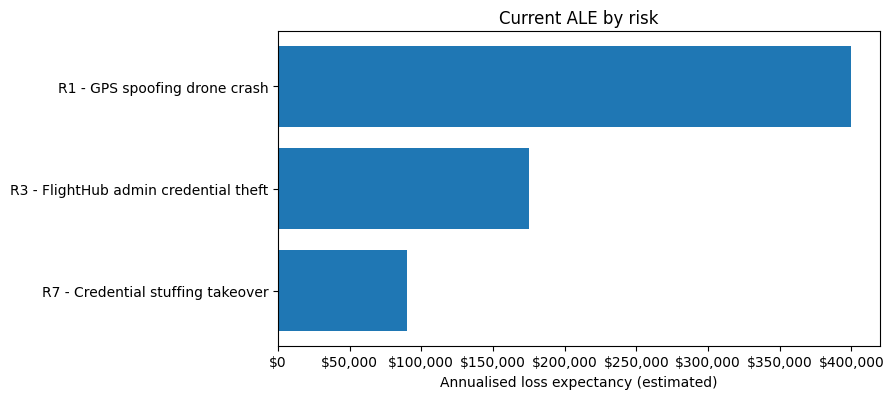

In [7]:
plot_data = risks_sorted.sort_values('ALE')

fig, ax = plt.subplots(figsize=(9, 0.7 * len(plot_data) + 2))
ax.barh(plot_data['Label'], plot_data['ALE'])
ax.xaxis.set_major_formatter(dollars)
ax.set_xlabel('Annualised loss expectancy (estimated)')
ax.set_title('Current ALE by risk')
finish('fig1_ale_ranking')

## 6. Figure 2: Current vs residual ALE

Compares expected annual loss before and after the proposed treatment.

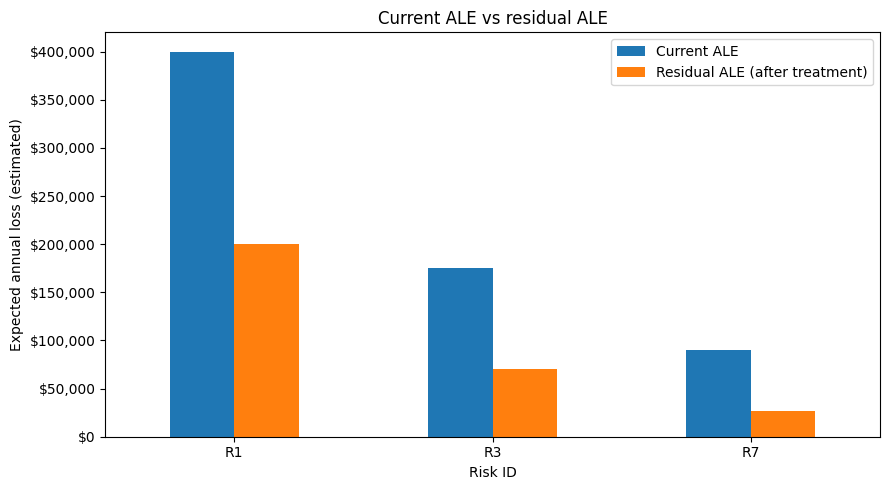

In [8]:
comparison = risks_sorted.set_index('Risk_ID')[['ALE', 'Residual_ALE']]
comparison.columns = ['Current ALE', 'Residual ALE (after treatment)']

ax = comparison.plot(kind='bar', figsize=(9, 5))
ax.yaxis.set_major_formatter(dollars)
ax.set_xlabel('Risk ID')
ax.set_ylabel('Expected annual loss (estimated)')
ax.set_title('Current ALE vs residual ALE')
plt.xticks(rotation=0)
finish('fig2_current_vs_residual')

## 7. Figure 3: Risk reduction compared with control cost

Compares the estimated annual risk reduction with the estimated annual cost of each control. Where the cost bar is taller than the reduction bar, the control costs more than the loss it is expected to avoid.

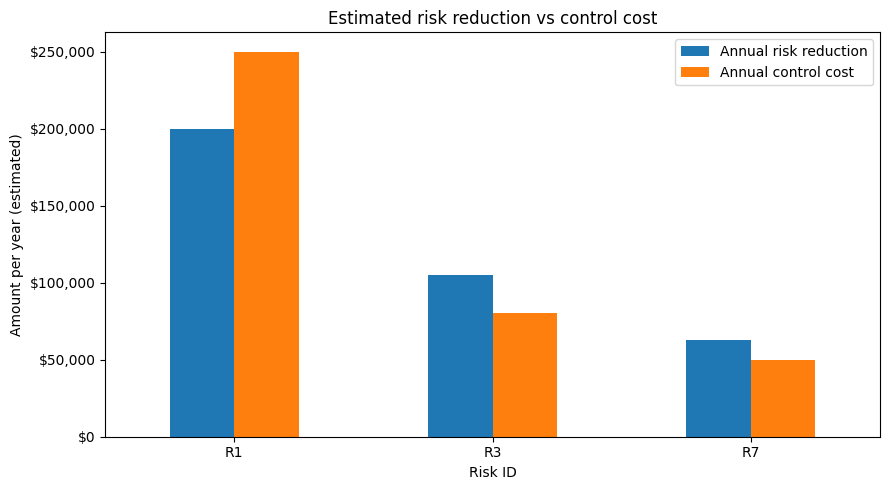

In [9]:
cost_comparison = risks_sorted.set_index('Risk_ID')[['Risk_Reduction', 'Control_Cost']]
cost_comparison.columns = ['Annual risk reduction', 'Annual control cost']

ax = cost_comparison.plot(kind='bar', figsize=(9, 5))
ax.yaxis.set_major_formatter(dollars)
ax.set_xlabel('Risk ID')
ax.set_ylabel('Amount per year (estimated)')
ax.set_title('Estimated risk reduction vs control cost')
plt.xticks(rotation=0)
finish('fig3_reduction_vs_cost')

## 8. Figure 4: Benefit-cost ratio

A ratio above 1 means the estimated annual risk reduction is greater than the estimated annual control cost. This is not a complete decision rule: legal, ethical, safety, and reputational reasons may justify a control whose ratio is below 1.

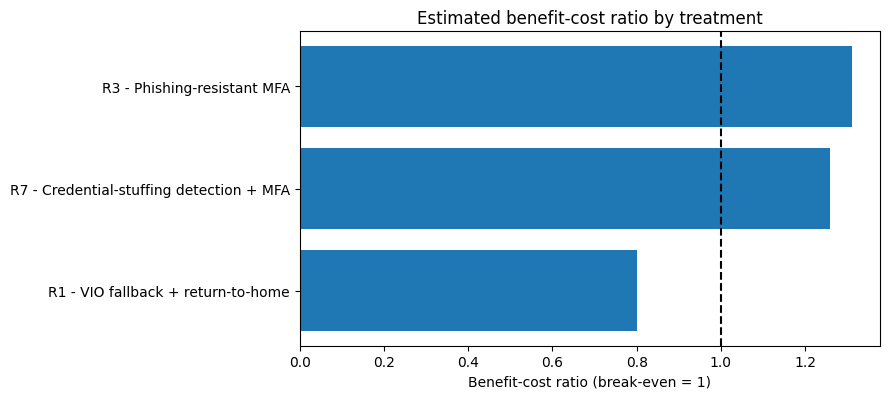

In [10]:
bcr_data = risks_sorted.dropna(subset=['Benefit_Cost_Ratio']).sort_values('Benefit_Cost_Ratio')

fig, ax = plt.subplots(figsize=(9, 0.7 * len(bcr_data) + 2))
ax.barh(bcr_data['Risk_ID'] + ' - ' + bcr_data['Control_Name'], bcr_data['Benefit_Cost_Ratio'])
ax.axvline(1, linestyle='--', color='black')
ax.set_xlabel('Benefit-cost ratio (break-even = 1)')
ax.set_title('Estimated benefit-cost ratio by treatment')
finish('fig4_benefit_cost_ratio')

## 9. Figure 5: Exposure bubble chart

Shows ARO (x-axis), SLE (y-axis) and ALE (bubble size) together. It separates risks that are rare but severe from those that are frequent but smaller, even when their ALE is the same.

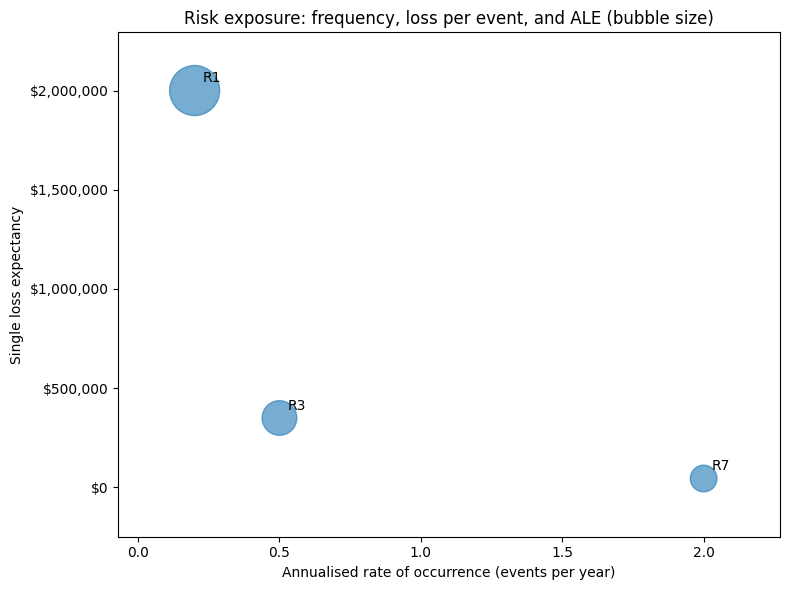

In [11]:
max_ale = risks['ALE'].max()
bubble_sizes = (risks['ALE'] / max_ale) * 1200 + 100 if max_ale > 0 else 300

fig, ax = plt.subplots(figsize=(8, 6))
ax.scatter(risks['ARO'], risks['SLE'], s=bubble_sizes, alpha=0.6)
for _, row in risks.iterrows():
    ax.annotate(row['Risk_ID'], (row['ARO'], row['SLE']), textcoords='offset points', xytext=(6, 6))
ax.yaxis.set_major_formatter(dollars)
ax.set_xlabel('Annualised rate of occurrence (events per year)')
ax.set_ylabel('Single loss expectancy')
ax.set_title('Risk exposure: frequency, loss per event, and ALE (bubble size)')
ax.margins(0.15)
finish('fig5_exposure_bubble')

## 10. Figure 6: Qualitative risk heatmap

Uses the `Likelihood_1_to_5` and `Impact_1_to_5` ratings and the same colour bands as the Practical 2 matrix. Risks that share a cell are listed together.

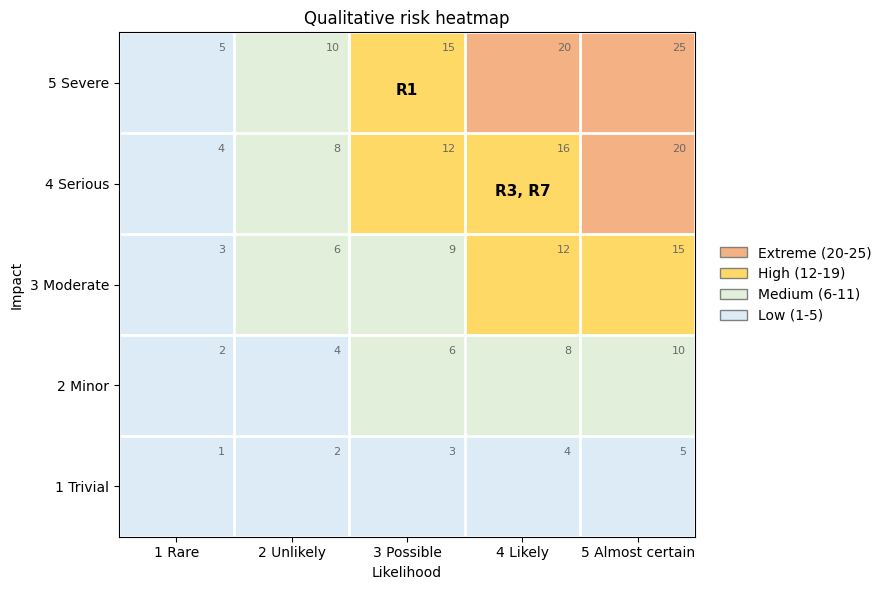

In [12]:
# Score grid with impact 5 on the top row
scores = np.array([[impact * likelihood for likelihood in range(1, 6)] for impact in range(5, 0, -1)])

band_colours = ['#DDEBF7', '#E2EFDA', '#FFD966', '#F4B183']   # Low, Medium, High, Extreme
cmap = ListedColormap(band_colours)
norm = BoundaryNorm([0, 5.5, 11.5, 19.5, 25.5], cmap.N)

fig, ax = plt.subplots(figsize=(9, 6))
ax.imshow(scores, cmap=cmap, norm=norm, aspect='auto')
ax.set_xticks(range(5))
ax.set_xticklabels(LIKELIHOOD_LABELS)
ax.set_yticks(range(5))
ax.set_yticklabels(IMPACT_LABELS[::-1])
ax.set_xlabel('Likelihood')
ax.set_ylabel('Impact')
ax.set_title('Qualitative risk heatmap')

# White grid lines between cells
ax.set_xticks(np.arange(-0.5, 5, 1), minor=True)
ax.set_yticks(np.arange(-0.5, 5, 1), minor=True)
ax.grid(which='minor', color='white', linewidth=2)
ax.tick_params(which='minor', length=0)

# Small score in the corner of each cell
for r in range(5):
    for col in range(5):
        ax.text(col + 0.42, r - 0.34, str(scores[r, col]), ha='right', va='center', fontsize=8, color='dimgray')

# Risk IDs, grouped so that risks sharing a cell do not overlap
def cell_label(ids):
    ids = list(ids)
    return '\n'.join(', '.join(ids[i:i + 2]) for i in range(0, len(ids), 2))   # two IDs per line

grouped = risks.groupby(['Likelihood_1_to_5', 'Impact_1_to_5'])['Risk_ID'].apply(cell_label)
for (likelihood, impact), label in grouped.items():
    crowded = label.count(',') + label.count('\n') >= 2
    ax.text(likelihood - 1, 5 - impact + 0.08, label, ha='center', va='center',
            fontweight='bold', fontsize=8.5 if crowded else 11)

legend_items = [Patch(facecolor=colour, edgecolor='gray', label=name) for colour, name in
                zip(band_colours[::-1], ['Extreme (20-25)', 'High (12-19)', 'Medium (6-11)', 'Low (1-5)'])]
ax.legend(handles=legend_items, loc='center left', bbox_to_anchor=(1.02, 0.5), frameon=False)
finish('fig6_heatmap')

## 11. Optional: incident-handling metrics

The Week 3 seminar also showed how monthly measurements can become metrics when tracked over time. The figures in this optional section are **illustrative demonstration data only**. They are not DJI observations and must not be presented as evidence about DJI in Assignment 1 unless replaced with supported data.

This section can be left unchanged for the practical or replaced later with verified organisation-specific incident data.

In [13]:
# Illustrative demonstration data only; these values are not DJI observations.
incident_inputs = pd.DataFrame({
    'Month': ['Jan', 'Feb', 'Mar', 'Apr', 'May', 'Jun'],
    'Security_Events': [420, 510, 470, 620, 580, 530],
    'Confirmed_Incidents': [8, 9, 7, 12, 10, 8],
    'Mean_Time_To_Detect_Hours': [38, 34, 29, 26, 22, 18],
    'Mean_Time_To_Recover_Hours': [72, 68, 60, 55, 48, 42]
})

incidents = incident_inputs.copy()
incidents['Incidents_per_100_Events'] = np.where(
    incidents['Security_Events'] > 0,
    incidents['Confirmed_Incidents'] / incidents['Security_Events'] * 100,
    np.nan
)
incidents

,Month,Security_Events,Confirmed_Incidents,Mean_Time_To_Detect_Hours,Mean_Time_To_Recover_Hours,Incidents_per_100_Events
0,Jan,420,8,38,72,1.90
1,Feb,510,9,34,68,1.76
2,Mar,470,7,29,60,1.49
3,Apr,620,12,26,55,1.94
4,May,580,10,22,48,1.72
5,Jun,530,8,18,42,1.51


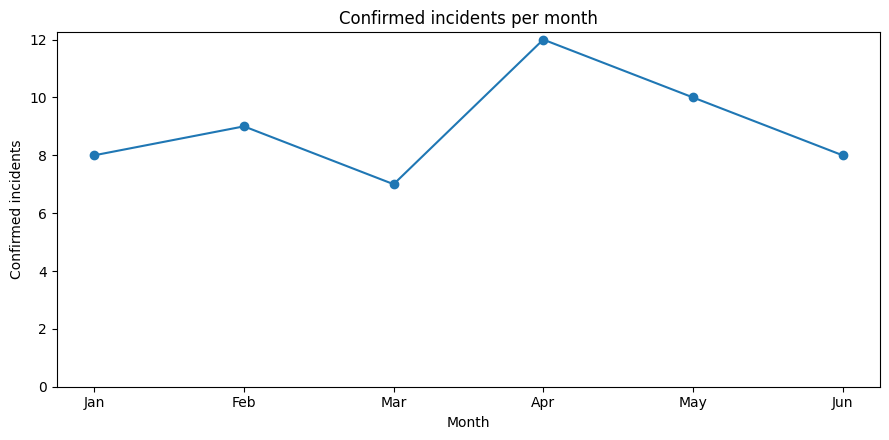

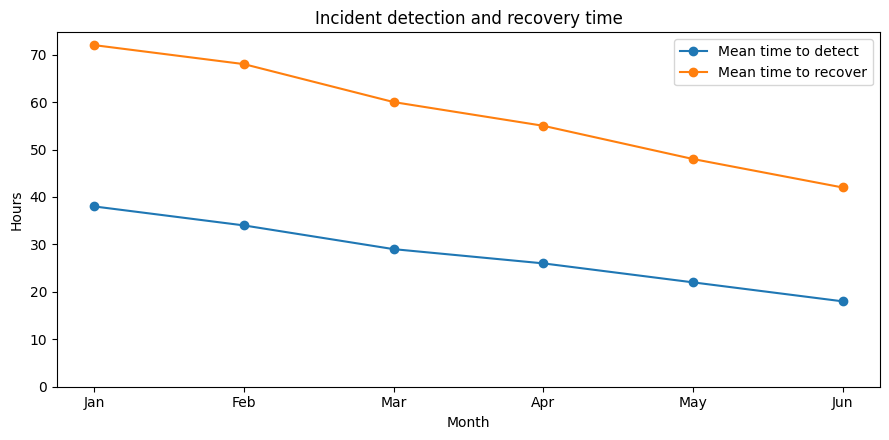

In [14]:
fig, ax = plt.subplots(figsize=(9, 4.5))
ax.plot(incidents['Month'], incidents['Confirmed_Incidents'], marker='o')
ax.set_ylim(bottom=0)
ax.set_xlabel('Month')
ax.set_ylabel('Confirmed incidents')
ax.set_title('Confirmed incidents per month')
finish('fig7_incident_counts')

fig, ax = plt.subplots(figsize=(9, 4.5))
ax.plot(incidents['Month'], incidents['Mean_Time_To_Detect_Hours'], marker='o', label='Mean time to detect')
ax.plot(incidents['Month'], incidents['Mean_Time_To_Recover_Hours'], marker='o', label='Mean time to recover')
ax.set_ylim(bottom=0)
ax.set_xlabel('Month')
ax.set_ylabel('Hours')
ax.set_title('Incident detection and recovery time')
ax.legend()
finish('fig8_incident_times')

## 12. Assumptions log

This log records the current quantitative assumptions used in the notebook. The figures are estimates for coursework analysis, not observed DJI internal data. Confidence indicates how strongly each estimate is supported at this stage.

| Risk ID | Value | Estimate | Source or reasoning | Confidence |
|---|---|---:|---|---|
| R3 | ARO | 0.50 | Assessment assumption informed by the Practical 2 Likelihood rating of 4 (Likely). No organisation-specific incident frequency is available in the supplied coursework materials. | Medium |
| R3 | SLE | $350,000 | Assessment assumption covering incident response/recovery, service disruption, customer notification/legal work, and plausible business loss from a privileged-account compromise. | Low |
| R3 | Control cost | $80,000/year | Estimated annual TCO for phishing-resistant MFA, identity administration, rollout/training, monitoring, and maintenance. | Medium |
| R3 | Likelihood reduction | 60% | Assessment assumption that phishing-resistant MFA materially reduces successful privileged credential compromise. The treatment is designed to reduce likelihood. | Medium |
| R7 | ARO | 2.00 | Assessment assumption informed by the Practical 2 Likelihood rating of 4 (Likely) and the persistent nature of credential-stuffing attacks. No DJI-specific frequency is available in the supplied materials. | Medium |
| R7 | SLE | $45,000 | Assessment assumption covering response/recovery, investigation, customer remediation/support, and operational disruption for a material account-takeover event. | Low |
| R7 | Control cost | $50,000/year | Estimated annual TCO for credential-stuffing detection, monitoring, MFA support, and operational maintenance. | Medium |
| R7 | Likelihood reduction | 70% | Assessment assumption for combined credential-stuffing detection and MFA. The treatment is designed primarily to reduce likelihood. | Medium |
| R1 | ARO | 0.20 | Assessment assumption informed by the Practical 2 Likelihood rating of 3 (Possible). No DJI-specific GPS-spoofing frequency is provided in the supplied materials. | Low |
| R1 | SLE | $2,000,000 | Assessment assumption representing a severe single-event case including emergency response, operational disruption, asset loss, legal/claims exposure, and major reputational consequences. | Low |
| R1 | Control cost | $250,000/year | Estimated annual TCO for engineering, testing, deployment, maintenance, and operational support for VIO fallback and signal-anomaly handling. | Low |
| R1 | Impact reduction | 50% | Assessment assumption that VIO fallback and return-to-home can materially reduce consequences when GPS signals are unreliable. The treatment is designed to reduce impact. | Low |

The next revision of this log should replace the weakest assumptions with stronger documentary, system, process, or expert evidence as required by Practical 4.

## 13. Current quantitative interpretation

The current assumptions are designed to illustrate three different exposure patterns while remaining aligned with the Practical 2 qualitative ratings:

- R1 is a low-frequency, very high-loss safety scenario and is expected to have the highest ALE.
- R3 has a moderate estimated frequency and high business impact, making it a financially important control case.
- R7 is more frequent but has a lower single-event loss, illustrating how frequent smaller events can accumulate substantial annual exposure.

The treatment calculations should be interpreted as decision-support estimates, not precise forecasts. Practical 4 will test how robust these conclusions remain when the weakest assumptions are replaced with ranges.